# 02 – Data Preparation: selecting predictors

**Goal of this step:** select, from many possible drivers, those that make sense for a
gradient-boosting model (XGBoost) of the Swiss day-ahead price. A correlation plot of all candidates
(multicorrelation matrix) shows two things:

1. **Relevance:** how strongly is a candidate related to the price?
2. **Redundancy:** which candidates measure almost the same thing? From such groups one is enough.

**Framework (from the EDA):**
- Period **from 2024**: before that, the Pronovo schema changes and the price regimes of the
  2022/23 crisis distort the picture. Weather forecasts from two days before are available at
  Open-Meteo from 20.01.2024.
- **Hourly**, because the Swiss price is hourly.
- **Forecast situation D+2:** on day D after the auction (~12:00), D+1 is known; D+2 is forecast.
  Every candidate is shifted the way it would be available at that time:

| Candidate | available at forecast time as |
|---|---|
| Swiss and neighbouring prices | lag ≥ 24 h (D+1 is known) |
| actual generation, trade (ENTSO-E) | lag 72 h |
| gas and CO2 price | daily value of D (2 days before the target day) |
| reservoir level (SFOE, weekly) | level of ≥ 7 days ago |
| weather for D+2 | weather forecast that existed on day D at 12:00 (Open-Meteo) |
| neighbouring prices *same hour** | **not available**, shown for comparison only |

Correlation only measures **monotonic** relationships. Calendar features (e.g. the hour with
morning and evening peak) are not monotonic and therefore look weak, although they matter for a
tree model. Mutual information complements the correlation for that reason.

**Result of this notebook:** the table `candidates` (all 46 candidates + 2 targets, hourly, gaps
filled), saved as `data/processed/candidates_d2.csv` for `03_modeling.ipynb` (Section 2.3), plus
the predictor selection (Section 6) and a pretest (Section 7).

## 0 Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from sklearn.feature_selection import mutual_info_regression

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import data_preparation as dp

FIG = ROOT / "figures" / "data_preparation"
FIG.mkdir(parents=True, exist_ok=True)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948",
          "#7a7a7a", "#00a3b4", "#a0522d"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": cycler(color=COLORS),
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 100, "savefig.dpi": 180, "savefig.bbox": "tight",
})
pd.set_option("display.float_format", "{:,.2f}".format)
GROUP_COLOR = dict(zip(dp.GROUPS, COLORS))


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name)

## 1 Load data

| Source | Content | Cache |
|---|---|---|
| energy-charts API via `analysis/01_fetch_data.py` | prices CH and neighbours, actual generation and load, trade, TSO forecasts (comparison only) | `analysis/data/` |
| Open-Meteo Previous Runs API | weather forecasts as issued 2 or 3 days before, for 35 points in CH, DE, FR, IT, AT | `data/raw/open_meteo/` |
| energy-charts.info chart data | filling level of the Swiss storage lakes (SFOE, weekly, from 2015) | `data/raw/energy_charts_web/` |
| energy-charts.info chart data | gas (THE) and CO2 price, marginal cost of a gas plant (daily) | `data/raw/energy_charts_web/` |

Everything is downloaded on the first run and read from the cache afterwards. If the hourly base
data set is missing, `dp.load_hourly()` starts the download itself (~30 min, because the
energy-charts API throttles requests).

In [2]:
hourly = dp.load_hourly()
storage = dp.load_storage_ch()
fuel = dp.load_fuel_prices()
weather = dp.load_weather_d2()
print(f"Hourly: {hourly.shape[0]:,} hours × {hourly.shape[1]} columns, "
      f"{hourly.index.min():%Y-%m-%d} – {hourly.index.max():%Y-%m-%d}")
print(f"Reservoir level: {len(storage)} weeks, {storage.index.min():%Y-%m-%d} – {storage.index.max():%Y-%m-%d}")
print(f"Gas/CO2: {len(fuel)} days, {fuel.index.min()} – {fuel.index.max()}")
complete = weather.notna().all(axis=1)
print(f"Weather forecast D+2: {weather.shape[1]} series, complete from {complete.idxmax():%Y-%m-%d}, "
      f"{complete.loc[complete.idxmax():].mean():.1%} of the hours complete afterwards")

Hourly: 24,648 hours × 154 columns, 2024-01-01 – 2026-10-23
Reservoir level: 613 weeks, 2015-01-05 – 2026-09-28
Gas/CO2: 1418 days, 2023-01-01 – 2026-11-18
Weather forecast D+2: 175 series, complete from 2024-02-18, 100.0% of the hours complete afterwards


### 1.1 The new sources at a glance

**Why this figure?** The reservoir level and the gas/CO2 price are new compared with the EDA.
Before they become candidates, we check whether they look plausible and in which form they belong
in the model.

**What we want to analyse:**
- Left: does the reservoir level follow the same curve every year? Then the level itself carries
  little information, only the **deviation from the usual level** of the same week.
- Right: does the Swiss price follow the cost of a gas plant, as the merit order suggests (the
  most expensive plant still needed sets the price)?

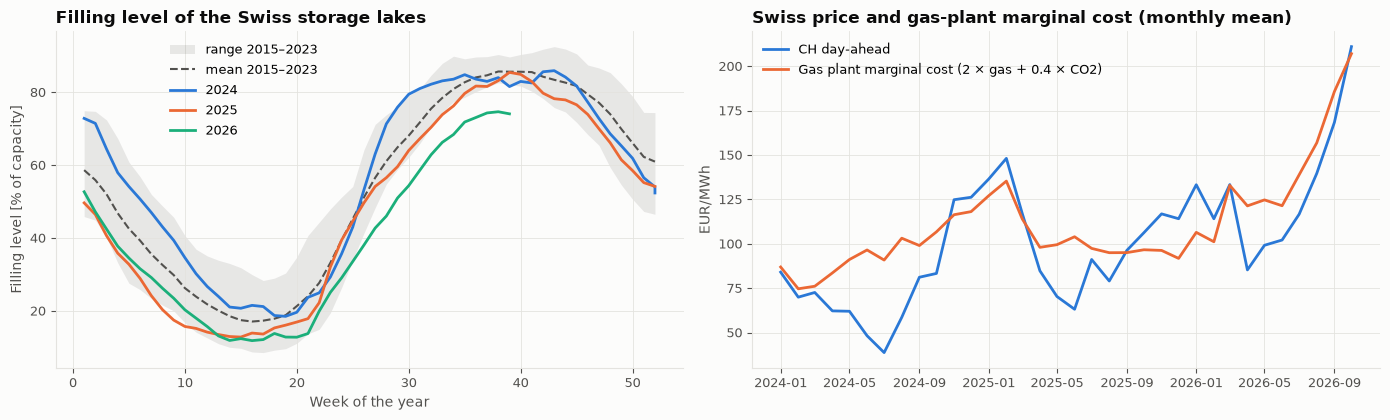

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
ax = axes[0]
st = storage.copy()
st["week"] = dp.storage_week(st.index)
clim = st[st.index.year <= 2023].groupby("week")["Reservoir level %"].agg(["mean", "min", "max"])
ax.fill_between(clim.index, clim["min"], clim["max"], color=INK_2, alpha=0.12, linewidth=0, label="range 2015–2023")
ax.plot(clim.index, clim["mean"], color=INK_2, linestyle="--", label="mean 2015–2023")
for year, color in zip((2024, 2025, 2026), COLORS):
    s = st[st.index.year == year]
    ax.plot(s["week"], s["Reservoir level %"], color=color, linewidth=2, label=str(year))
ax.set_title("Filling level of the Swiss storage lakes")
ax.set_xlabel("Week of the year")
ax.set_ylabel("Filling level [% of capacity]")
ax.legend(loc="upper center", bbox_to_anchor=(0.3, 1))

ax = axes[1]
monthly_price = hourly["price_ch"].tz_convert(dp.TZ).resample("MS").mean().tz_localize(None)
f = fuel.copy()
f.index = pd.to_datetime(f.index)
monthly_fuel = f.resample("MS").mean().loc[monthly_price.index.min():monthly_price.index.max()]
ax.plot(monthly_price.index, monthly_price, color=COLORS[0], linewidth=2, label="CH day-ahead")
ax.plot(monthly_fuel.index, monthly_fuel["Gas plant marginal cost"], color=COLORS[1], linewidth=2,
        label="Gas plant marginal cost (2 × gas + 0.4 × CO2)")
ax.set_title("Swiss price and gas-plant marginal cost (monthly mean)")
ax.set_ylabel("EUR/MWh")
ax.legend(loc="upper left")
save(fig, "01_new_sources.png")

**What we see:**
- The reservoir level follows the same curve every year: low point in April, peak in September.
  The level alone is therefore almost only a calendar. In spring 2024 it was clearly above the mean
  (~+10 percentage points), from 2025 below it. This deviation becomes the candidate **Reservoir
  level anomaly**.
- The Swiss price and the gas-plant marginal cost run in parallel in the monthly mean. The gas
  price therefore mainly explains the **level** over months, not the swings within a day.

### 1.2 Weather forecast for D+2

**Problem:** the TSOs publish their forecasts for solar, wind and load only for the **next** day.
The forecast for D+2 therefore appears in the evening of D+1, after our forecast time:

```
Day D,   ~12:00   auction → prices for D+1 known → we forecast D+2
Day D+1, ~18:00   TSO forecast for D+2 is published   ← too late
```

A model trained with these forecasts would use knowledge from the future and look better than it
would be in operation.

**Solution:** weather forecasts reach several days ahead. They go **directly** into the price model
as predictors: temperature, radiation and wind at 100 m per country (CH, DE, FR, IT, AT), as the
mean of several points. The price model learns by itself that, for example, strong wind in northern
Germany lowers the price.

**Why archived forecasts and not measured weather?** Training needs the forecasts **as they were
issued at the time**, including their errors. With measured weather, the model would know the
weather of D+2 perfectly and rely on it too much. Open-Meteo archives what a weather model predicted
**2 or 3 days before** the target hour. For each hour of D+2 we take the run that was already
published at 12:00 on day D (early hours: 2 days before, all others: 3 days before).

**Why this figure?** The weather forecast replaces the TSO production forecast. We check how well
it matches the actual production, using German wind (the largest single driver of price swings).

**What we want to analyse:** does production rise with the forecast wind speed, and how wide is the
spread? Does the forecast for D+2 follow the large swings of a week?

Spearman ρ wind forecast (D+2) ↔ wind production DE: +0.89


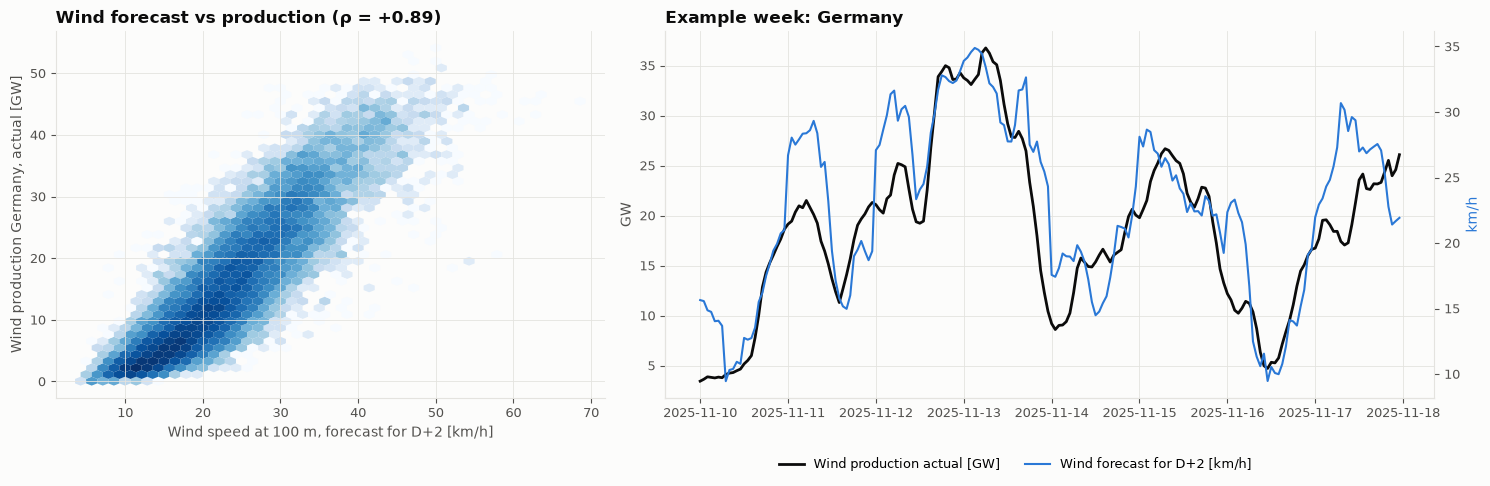

In [4]:
wind_actual = hourly[["act_de_wind_onshore", "act_de_wind_offshore"]].sum(axis=1, min_count=2) / 1000
wind_fc = weather[[f"de_{p}_wind_speed_100m" for p in dp.WEATHER_POINTS["de"]]].mean(axis=1).reindex(wind_actual.index)
d = pd.concat({"forecast": wind_fc, "actual": wind_actual}, axis=1).dropna()
rho_wind = d.corr(method="spearman").iloc[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.hexbin(d["forecast"], d["actual"], gridsize=45, bins="log", cmap="Blues", mincnt=1, linewidths=0)
ax.set_xlabel("Wind speed at 100 m, forecast for D+2 [km/h]")
ax.set_ylabel("Wind production Germany, actual [GW]")
ax.set_title(f"Wind forecast vs production (ρ = {rho_wind:+.2f})")

ax = axes[1]
week = slice("2025-11-10", "2025-11-17")
ax.plot(wind_actual.loc[week].index, wind_actual.loc[week], color=INK, linewidth=2, label="Wind production actual [GW]")
ax.set_ylabel("GW")
ax2 = ax.twinx()
ax2.plot(wind_fc.loc[week].index, wind_fc.loc[week], color=COLORS[0], label="Wind forecast for D+2 [km/h]")
ax2.set_ylabel("km/h", color=COLORS[0])
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title("Example week: Germany")
fig.legend(loc="upper center", bbox_to_anchor=(0.68, 0.02), ncol=2)
save(fig, "02_weather_forecast_d2.png")
print(f"Spearman ρ wind forecast (D+2) ↔ wind production DE: {rho_wind:+.2f}")

**What we see:**
- Production rises clearly with the forecast wind speed (ρ +0.89). Below ~10 km/h it stays close
  to zero; above that it rises almost evenly. The weather forecast for D+2 therefore carries most
  of the information a forecast in MW would have.
- The cloud is wide: the same wind speed leads to different production (forecast errors two days
  ahead, curtailment, new turbines over time).
- In the example week the forecast follows the large changes between windy and calm days. These
  changes are what moves the price.

A separate intermediate model that converts the weather into solar, wind and load production in MW
could make this conversion more precise. It is described as a possible extension in the README.

## 2 Candidate predictors

`dp.build_candidates` creates all 46 candidates with the shifts of the D+2 situation. In addition to
the target **Price CH**, **Δ Price CH vs previous day** (price − price 24 h earlier) is examined: a
model that predicts the change against yesterday needs different predictors than one that predicts
the level.

So that the lags are not empty in the first days of 2024, December 2023 is loaded as a lead-in
(`dp.load_warmup_2023`: prices CH and neighbours, actual generation CH/FR, trade). The lags are
computed from it; afterwards the table is cut to 2024.

The complete table is then stored in the variable **`candidates`** (one row per hour, index UTC,
46 predictors + 2 targets).

In [5]:
warmup = dp.load_warmup_2023()
extended = pd.concat([warmup, hourly]).sort_index()
candidates_raw = dp.build_candidates(extended, storage, fuel, weather).loc[dp.START:]
print(f"{candidates_raw.shape[1] - 2} candidates, {len(candidates_raw):,} hours "
      f"({candidates_raw.index.min():%Y-%m-%d} – {candidates_raw.index.max():%Y-%m-%d})")

46 candidates, 24,648 hours (2024-01-01 – 2026-10-23)


### 2.1 What each predictor is

**Table: all 46 candidates**, including those left out later. *Type* states which values are
possible: **continuous** = any number with a unit, **binary** = only 0 or 1, **cyclic** =
sine/cosine between −1 and 1, **percent/percentage points** = a share or a deviation from it.
*Available as* states the delay with which the value is known at forecast time (day D, 12:00).
*Decision* summarises the result of Sections 3–6.

**Why sine and cosine?** As a number 0–23, 23:00 and 00:00 would be far apart although they are
neighbours. On a circle (sine and cosine together) they lie next to each other; the same holds for
December and January.

In [6]:
dp.predictor_table().style.set_properties(subset=["Meaning"], **{"text-align": "left", "white-space": "normal"})

,Group,Type,Unit,Meaning,Available as,Decision
Predictor,,,,,,
CH lag 24h,CH price lags,continuous,EUR/MWh,"Swiss price in the same hour on the previous day (D+1, already known)",lag 24 h,keep
CH lag 48h,CH price lags,continuous,EUR/MWh,Swiss price in the same hour two days earlier,lag 48 h,drop
CH lag 168h,CH price lags,continuous,EUR/MWh,Swiss price in the same hour one week earlier (same weekday),lag 168 h,keep
CH mean previous day,CH price lags,continuous,EUR/MWh,daily mean of the Swiss price on the previous day,day D+1,drop
CH mean 7 days,CH price lags,continuous,EUR/MWh,mean of the last 7 daily means: current price level,up to D+1,keep
DE lag 24h,Neighbour prices (lag 24h),continuous,EUR/MWh,"German/Luxembourg price, same hour, previous day",lag 24 h,test in model
FR lag 24h,Neighbour prices (lag 24h),continuous,EUR/MWh,"French price, same hour, previous day",lag 24 h,test in model
IT-North lag 24h,Neighbour prices (lag 24h),continuous,EUR/MWh,"North Italian price, same hour, previous day",lag 24 h,drop
AT lag 24h,Neighbour prices (lag 24h),continuous,EUR/MWh,"Austrian price, same hour, previous day",lag 24 h,drop


### 2.2 Filling missing values

After the lead-in from 2023 only a few values are missing: single hours in the sources (e.g. at the
daylight-saving change) and a long block in the weather forecasts. `dp.fill_gaps` fills each gap
with the value of the **same hour on the previous day** and, where that is missing, **of the
previous week**. This matches the daily and weekly structure of the electricity market
(autocorrelation, EDA 5.4).

Only gaps of up to 7 days in a row are filled. **Not fillable** is the block from 01.01. to
17.02.2024 in the weather forecasts: Open-Meteo has forecasts from two days before only from
20.01.2024 (wind at 100 m from 18.02.2024), and none at all for 2023. A previous-day value would be
invented there. The modelling data set therefore starts on **18.02.2024**; XGBoost could handle
missing values, but would learn without weather information in those weeks.

In [7]:
candidates, gap_report = dp.fill_gaps(candidates_raw)
gap_report.sort_values("missing", ascending=False)

,missing,previous day,previous week,still empty
Predictor,,,,
Wind 100m DE (D+2),1151,0,0,1151
Wind 100m IT (D+2),1151,0,0,1151
Wind 100m AT (D+2),1151,0,0,1151
Wind 100m CH (D+2),1151,0,0,1151
Wind 100m FR (D+2),1151,0,0,1151
Precipitation 7 days CH,508,0,0,508
Radiation AT (D+2),485,0,0,485
Temperature CH (D+2),485,0,0,485
Radiation CH (D+2),485,0,0,485


### 2.3 Data set for the modelling

`candidates` is saved as a CSV and is thus available for `03_modeling.ipynb` without repeating the
downloads. The file lies under `data/` and is therefore not versioned; it is recreated on every run
of this notebook.

In [8]:
dp.DATASET_CSV.parent.mkdir(parents=True, exist_ok=True)
candidates.rename_axis("time_utc").to_csv(dp.DATASET_CSV)
print(f"{dp.DATASET_CSV.relative_to(ROOT)}: {candidates.shape[0]:,} hours × {candidates.shape[1]} columns")
overview = pd.DataFrame({
    "Group": [dp.GROUP_OF[c] for c in candidates],
    "Coverage before": candidates_raw.notna().mean(),
    "Coverage after": candidates.notna().mean(),
    "Median": candidates.median(),
}).rename_axis("Candidate")
overview.style.format({"Coverage before": "{:.1%}", "Coverage after": "{:.1%}", "Median": "{:,.1f}"})

data/processed/candidates_d2.csv: 24,648 hours × 48 columns


,Group,Coverage before,Coverage after,Median
Candidate,,,,
Price CH,Target,100.0%,100.0%,101.8
Δ Price CH vs previous day,Target,100.0%,100.0%,-0.5
CH lag 24h,CH price lags,100.0%,100.0%,101.6
CH lag 48h,CH price lags,100.0%,100.0%,101.5
CH lag 168h,CH price lags,100.0%,100.0%,101.0
CH mean previous day,CH price lags,100.0%,100.0%,99.3
CH mean 7 days,CH price lags,100.0%,100.0%,98.0
DE lag 24h,Neighbour prices (lag 24h),100.0%,100.0%,92.1
FR lag 24h,Neighbour prices (lag 24h),100.0%,100.0%,65.0


## 3 Multicorrelation matrix

**Why this figure?** 46 candidates are too many, and many probably measure the same thing (e.g. the
prices of the neighbouring countries or the temperature in five countries). The matrix compares
**every candidate with every other one**.

**What we want to analyse:** dark blocks away from the diagonal. They show groups that carry almost
the same information; one representative per group is enough. The top two rows (targets) also give
a first impression of relevance.

**How to read it:** Spearman rank correlation ρ. Blue = same direction, red = opposite direction,
the stronger the colour the stronger the relationship; values with |ρ| ≥ 0.7 are labelled. The
coloured bars at the edge mark the groups. Spearman instead of Pearson, because the price
distribution has heavy tails (EDA 3.2) and Spearman uses only the ranks: single extreme prices
(−464 EUR/MWh) do not distort the result, and monotonic but curved relationships (wind curve) count
fully.

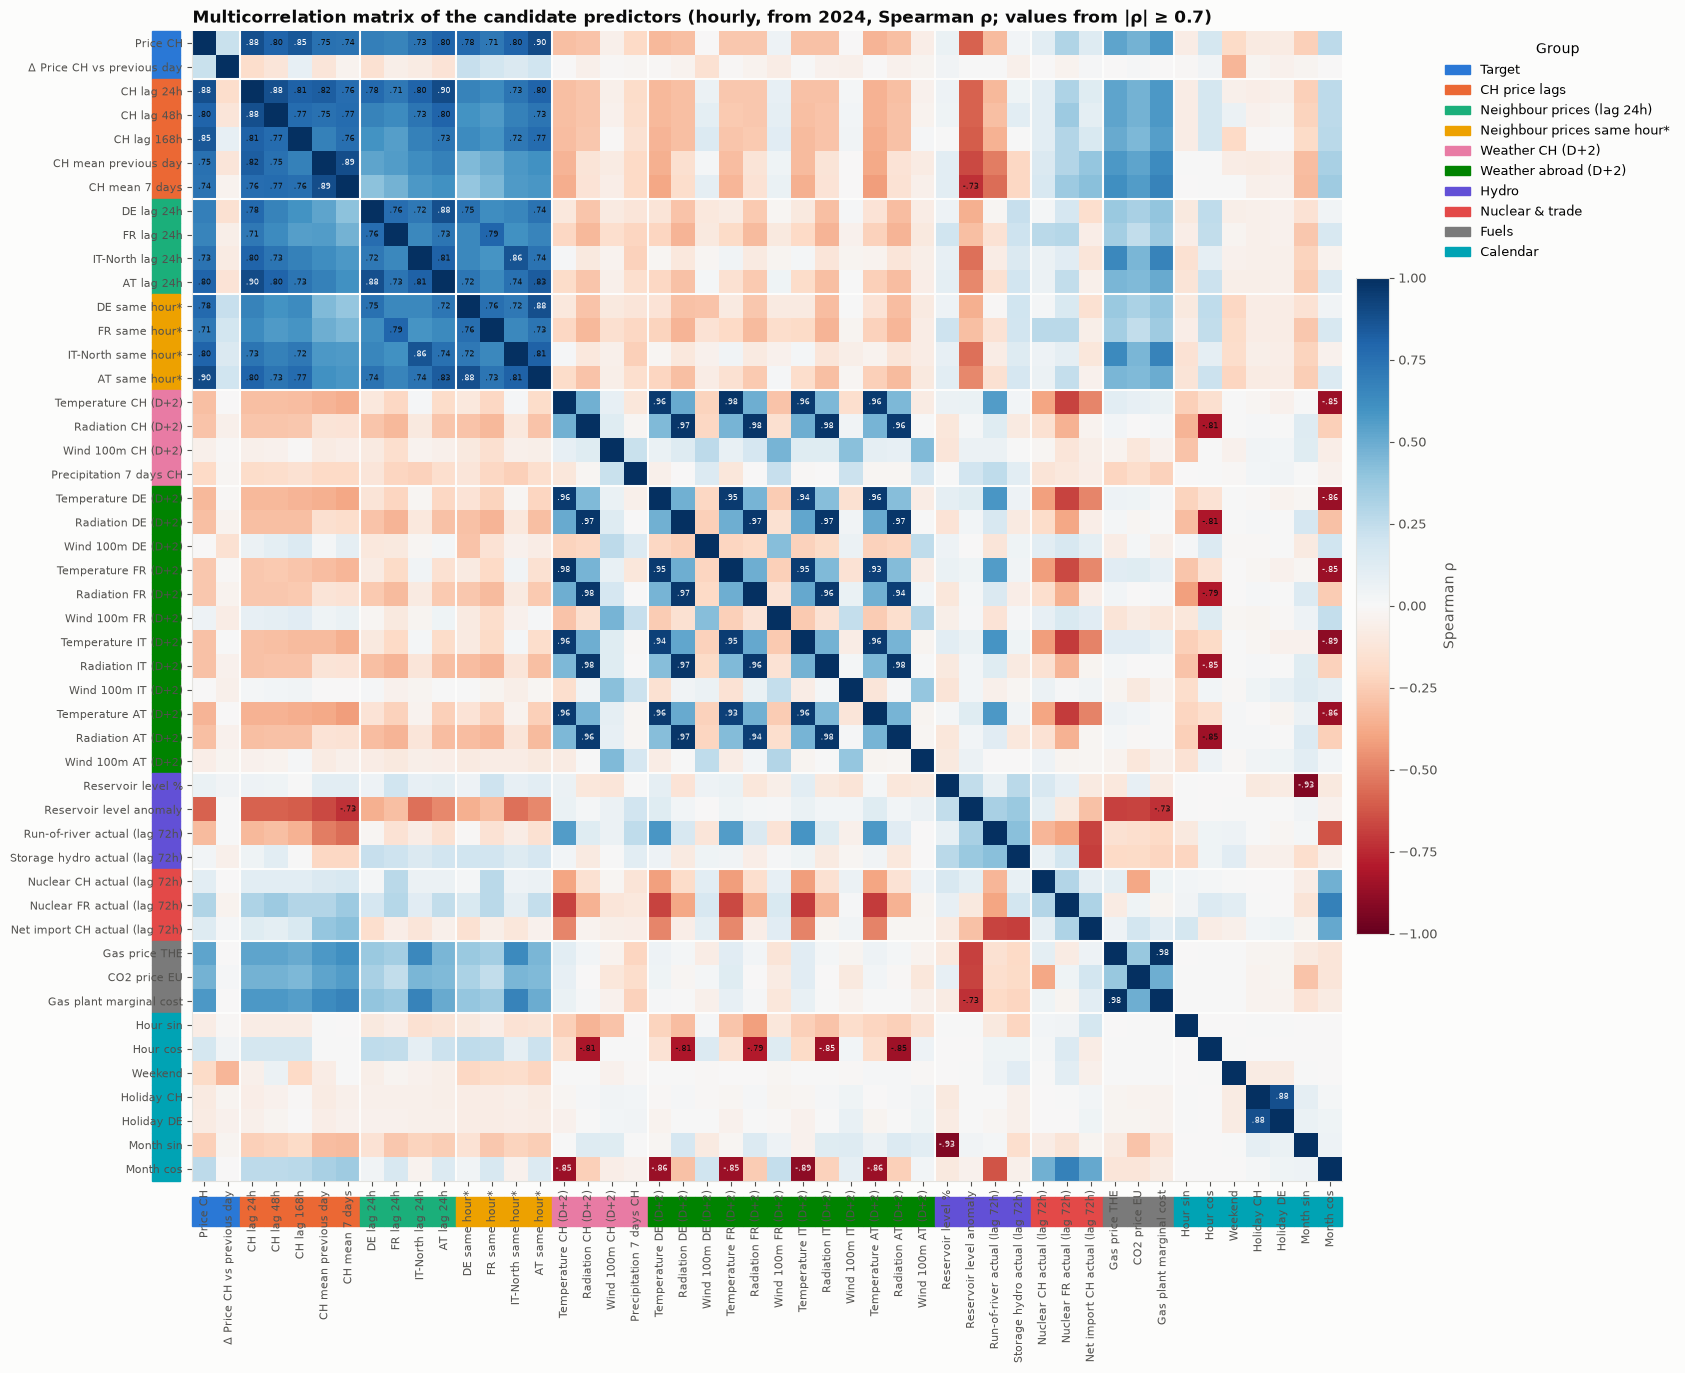

In [9]:
corr = candidates.corr(method="spearman")
cols = list(corr.columns)
n = len(cols)
fig, ax = plt.subplots(figsize=(17, 15))
im = ax.imshow(corr.to_numpy(), cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(n), cols, rotation=90, fontsize=8)
ax.set_yticks(range(n), cols, fontsize=8)
ax.grid(False)
# group borders and colour bars
edges = np.cumsum([len(v) for v in dp.GROUPS.values()])[:-1] - 0.5
for e in edges:
    ax.axhline(e, color=SURFACE, linewidth=1.5)
    ax.axvline(e, color=SURFACE, linewidth=1.5)
for i, c in enumerate(cols):
    color = GROUP_COLOR[dp.GROUP_OF[c]]
    ax.add_patch(plt.Rectangle((-2.2, i - 0.5), 1.2, 1, color=color, clip_on=False))
    ax.add_patch(plt.Rectangle((i - 0.5, n + 0.2), 1, 1.2, color=color, clip_on=False))
# label only strong relationships (otherwise unreadable)
for i in range(n):
    for j in range(n):
        v = corr.iat[i, j]
        if i != j and abs(v) >= 0.7:
            ax.text(j, i, f"{v:.2f}".replace("0.", "."), ha="center", va="center", fontsize=5.5,
                    color="white" if abs(v) > 0.85 else INK)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOR[g]) for g in dp.GROUPS]
ax.legend(handles, dp.GROUPS, loc="upper left", bbox_to_anchor=(1.08, 1), title="Group", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.5, pad=0.01, label="Spearman ρ")
ax.set_title("Multicorrelation matrix of the candidate predictors (hourly, from 2024, Spearman ρ; values from |ρ| ≥ 0.7)")
save(fig, "03_multicorrelation.png")

**What we see:**
- **Price lags and neighbouring prices** form one large block (ρ 0.8–0.9): the electricity market is
  coupled, yesterday's neighbouring prices say almost the same as yesterday's Swiss price.
- **Temperature and radiation** are almost identical across all five countries (ρ 0.93–0.98): the
  weather in central Europe is large-scale. One series per quantity is enough.
- **Wind**, in contrast, differs clearly by country (ρ 0.06–0.47): North Sea wind in Germany is a
  different signal from wind in the Alps.
- Gas price and gas-plant marginal cost are almost the same (ρ 0.98), as are reservoir level % and
  month (ρ −0.93).

## 4 Relevance for the target

**Why this figure?** The matrix shows redundancy, but not clearly which candidate has anything to
do with the price at all. Here every candidate is set against the targets on its own.

**What we want to analyse:** which candidates relate to the **price level**, which to the **change
against the previous day**, and which to neither?

- **Spearman ρ with the price:** monotonic relationship with the price level.
- **Spearman ρ with Δ price:** relationship with the change against the previous day.
- **Mutual information with the price:** also captures non-monotonic relationships (e.g. time of
  day). It has no fixed upper bound; only the values are compared with each other.

**Caution with slow variables:** reservoir level, gas/CO2 price, 7-day mean and actual nuclear power
change only daily or weekly. Over only 2.8 years they act almost like a date stamp: they "know"
which phase it is, and thus the price level of that time. Mutual information and partly also ρ
therefore overrate them. Whether they really help is only shown by a test on a separate period.

,ρ price,ρ Δ price,MI price,Group
AT same hour*,+0.90,+0.20,1.15,Neighbour prices same hour*
CH lag 24h,+0.88,-0.17,0.95,CH price lags
CH lag 168h,+0.85,+0.09,0.76,CH price lags
CH lag 48h,+0.80,-0.12,0.67,CH price lags
AT lag 24h,+0.80,-0.14,0.65,Neighbour prices (lag 24h)
IT-North same hour*,+0.80,+0.14,0.83,Neighbour prices same hour*
DE same hour*,+0.78,+0.23,0.87,Neighbour prices same hour*
CH mean previous day,+0.75,-0.12,0.64,CH price lags
CH mean 7 days,+0.74,-0.03,0.66,CH price lags
IT-North lag 24h,+0.73,-0.08,0.59,Neighbour prices (lag 24h)


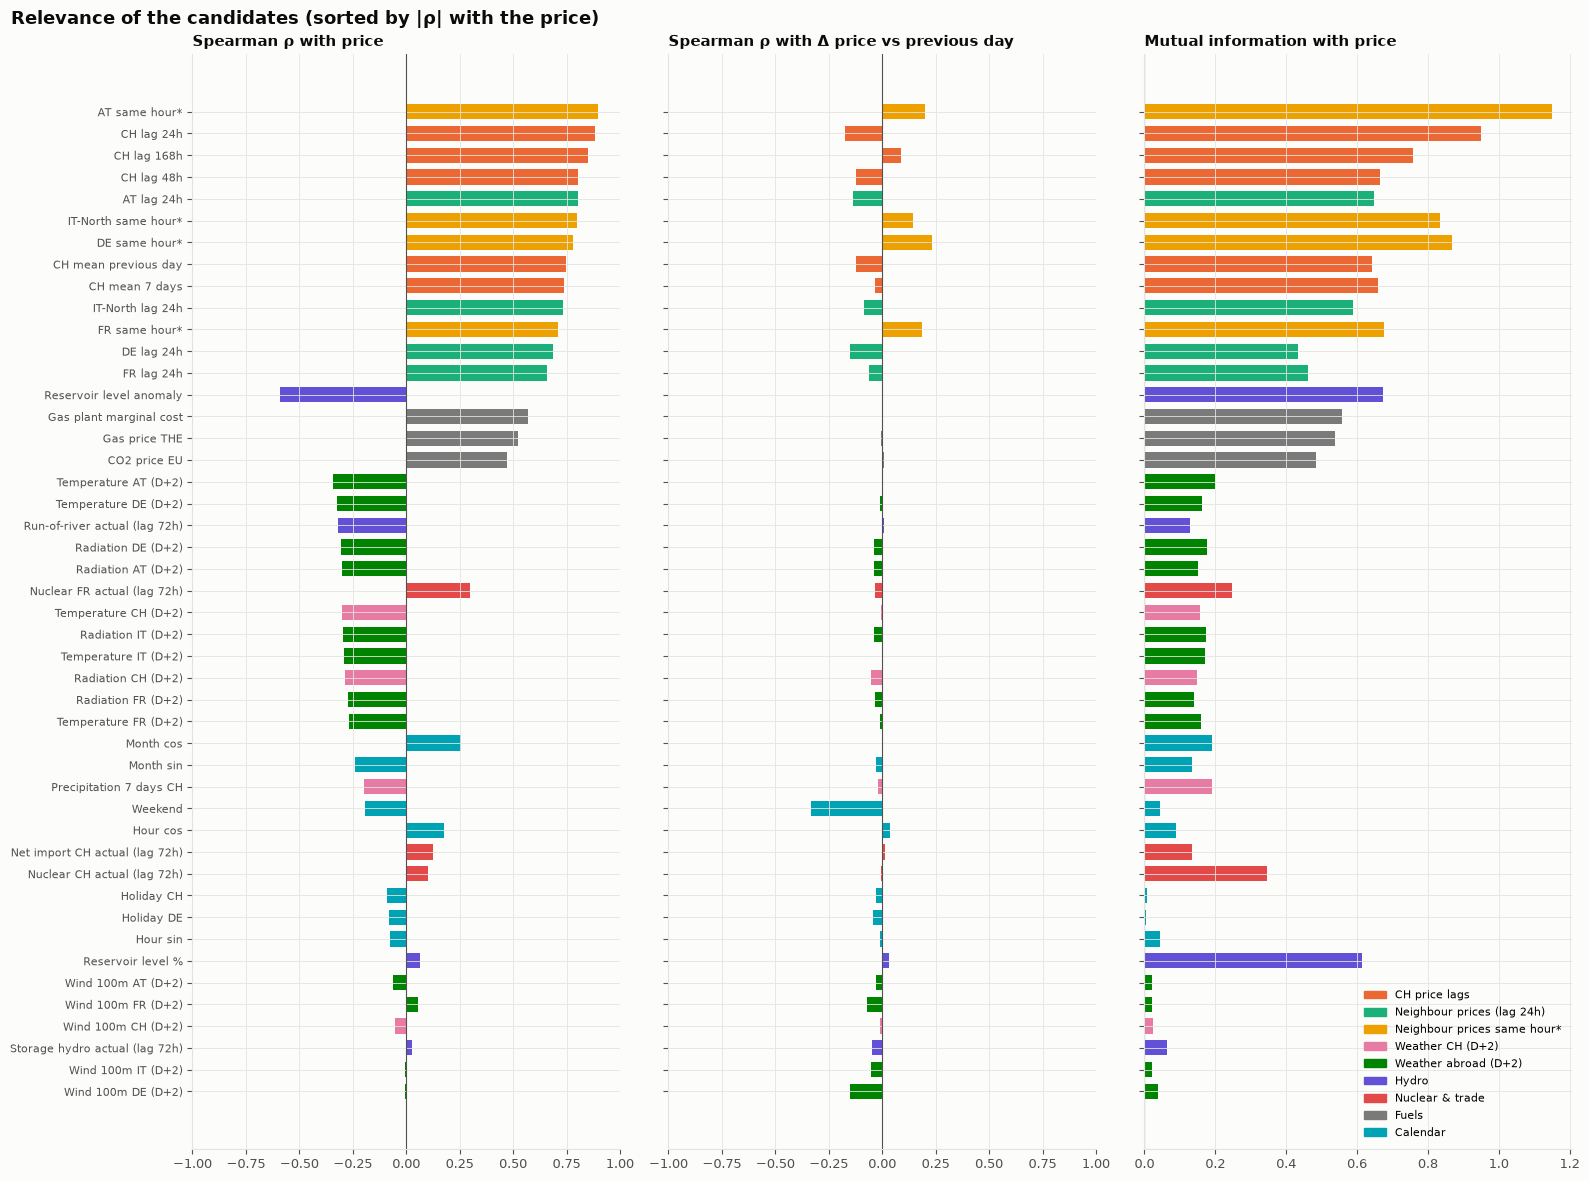

In [10]:
feats = [c for c in candidates if dp.GROUP_OF[c] != "Target"]
sample = candidates.dropna().sample(n=min(12_000, len(candidates.dropna())), random_state=0)
mi = pd.Series(mutual_info_regression(sample[feats], sample[dp.TARGET], random_state=0), index=feats)
relevance = pd.DataFrame({
    "ρ price": corr.loc[feats, dp.TARGET],
    "ρ Δ price": corr.loc[feats, dp.TARGET_DELTA],
    "MI price": mi,
    "Group": [dp.GROUP_OF[c] for c in feats],
}).sort_values("ρ price", key=np.abs)

fig, axes = plt.subplots(1, 3, figsize=(16, 12), sharey=True)
colors = [GROUP_COLOR[g] for g in relevance["Group"]]
for ax, col, title in zip(axes, ["ρ price", "ρ Δ price", "MI price"],
                          ["Spearman ρ with price", "Spearman ρ with Δ price vs previous day", "Mutual information with price"]):
    ax.barh(relevance.index, relevance[col], color=colors, height=0.7)
    ax.axvline(0, color=INK_2, linewidth=0.8)
    ax.set_title(title, fontsize=11)
    ax.tick_params(axis="y", labelsize=8)
axes[0].set_xlim(-1, 1)
axes[1].set_xlim(-1, 1)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOR[g]) for g in dp.GROUPS if g != "Target"]
axes[2].legend(handles, [g for g in dp.GROUPS if g != "Target"], loc="lower right", fontsize=8)
fig.suptitle("Relevance of the candidates (sorted by |ρ| with the price)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=INK)
save(fig, "04_relevance.png")
relevance.sort_values("ρ price", key=np.abs, ascending=False).style.format(
    {"ρ price": "{:+.2f}", "ρ Δ price": "{:+.2f}", "MI price": "{:.2f}"}).bar(
    subset=["MI price"], color="#c8daf2")

**What we see:**
- **Price level:** strongest are the prices of yesterday and last week (ρ 0.85–0.88), then the
  reservoir level anomaly (−0.59) and the gas-plant marginal cost (+0.57). Temperature and radiation
  act in the opposite direction (ρ ≈ −0.3): warm and sunny → more solar, less heating → cheaper.
- **Change against the previous day:** almost everything is weak here. The clearest signals are the
  weekend (−0.34) and German wind (−0.15): more wind than yesterday makes electricity cheaper.
- **No relationship:** wind CH, IT and AT, storage hydro and reservoir level % (|ρ| ≤ 0.06).
- The neighbouring prices in the *same hour* are the strongest (AT ρ 0.90), but unknown for D+2.

## 5 Redundancy

### 5.1 Strongly correlated pairs (|ρ| ≥ 0.9)
For such pairs the second predictor carries hardly any additional information. Tree models do not
break because of that, but the importance is split randomly between both, which makes the
explanation (SHAP) harder.

In [11]:
dp.redundant_pairs(corr, 0.9)

,Predictor A,Predictor B,ρ
0,Gas price THE,Gas plant marginal cost,0.98
1,Temperature CH (D+2),Temperature FR (D+2),0.98
2,Radiation IT (D+2),Radiation AT (D+2),0.98
3,Radiation CH (D+2),Radiation FR (D+2),0.98
4,Radiation CH (D+2),Radiation IT (D+2),0.98
5,Radiation CH (D+2),Radiation DE (D+2),0.97
6,Radiation DE (D+2),Radiation IT (D+2),0.97
7,Radiation DE (D+2),Radiation AT (D+2),0.97
8,Radiation DE (D+2),Radiation FR (D+2),0.97
9,Radiation FR (D+2),Radiation IT (D+2),0.96


### 5.2 Clusters and suggestion per cluster

Hierarchical clustering with the distance 1 − |ρ|: predictors with |ρ| ≥ 0.8 end up in the same
cluster. Per cluster the candidate with the highest mutual information is suggested as the
**representative**. Clusters with only one member are not redundant.

In [12]:
clusters = dp.cluster_shortlist(corr, relevance["MI price"], threshold=0.2)
multi = clusters[clusters.groupby("Cluster")["Cluster"].transform("size") > 1]
multi.style.format({"Relevance": "{:.2f}"}).apply(
    lambda r: ["font-weight: bold" if r["Representative"] else "" for _ in r], axis=1)

,Cluster,Group,Relevance,Representative
Reservoir level %,7,Hydro,0.61,True
Month sin,7,Calendar,0.13,False
CH mean 7 days,8,CH price lags,0.66,True
CH mean previous day,8,CH price lags,0.64,False
AT same hour*,12,Neighbour prices same hour*,1.15,True
DE same hour*,12,Neighbour prices same hour*,0.87,False
IT-North same hour*,13,Neighbour prices same hour*,0.83,True
IT-North lag 24h,13,Neighbour prices (lag 24h),0.59,False
CH lag 24h,14,CH price lags,0.95,True
CH lag 48h,14,CH price lags,0.67,False


### 5.3 Why these candidates are left out

**Why this figure?** The tables above say *that* a candidate is left out. The figure shows for each
one *why*, so the decision can be checked.

**What we want to analyse:**
- **Redundant** (blue): candidate against the kept representative. If the points lie on a narrow
  diagonal, the candidate measures the same thing and adds no new information.
- **No relationship** (red): candidate against the Swiss price. A shapeless cloud with ρ ≈ 0 means
  that the price is distributed the same at high and low values.
- **Wind per country** (bars): ρ with the price and with the change against the previous day, to
  show which wind is kept.
- **Holiday DE:** as a table, because both quantities are only 0 or 1.

Dark areas = many hours. The axes show P0.5–P99.5; extreme prices remain included in ρ. Temperature
and radiation of the four neighbouring countries share one panel each.

,Compared with,ρ with price,ρ with Δ price,ρ with reference
CH lag 48h,CH lag 24h,+0.80,-0.12,+0.88
AT lag 24h,CH lag 24h,+0.80,-0.14,+0.90
IT-North lag 24h,CH lag 24h,+0.73,-0.08,+0.80
CH mean previous day,CH mean 7 days,+0.75,-0.12,+0.89
Gas price THE,Gas plant marginal cost,+0.53,-0.01,+0.98
Temperature DE (D+2),Temperature CH (D+2),-0.32,-0.01,+0.96
Temperature FR (D+2),Temperature CH (D+2),-0.27,-0.01,+0.98
Temperature IT (D+2),Temperature CH (D+2),-0.29,+0.00,+0.96
Temperature AT (D+2),Temperature CH (D+2),-0.34,-0.00,+0.96
Radiation DE (D+2),Radiation CH (D+2),-0.30,-0.04,+0.97


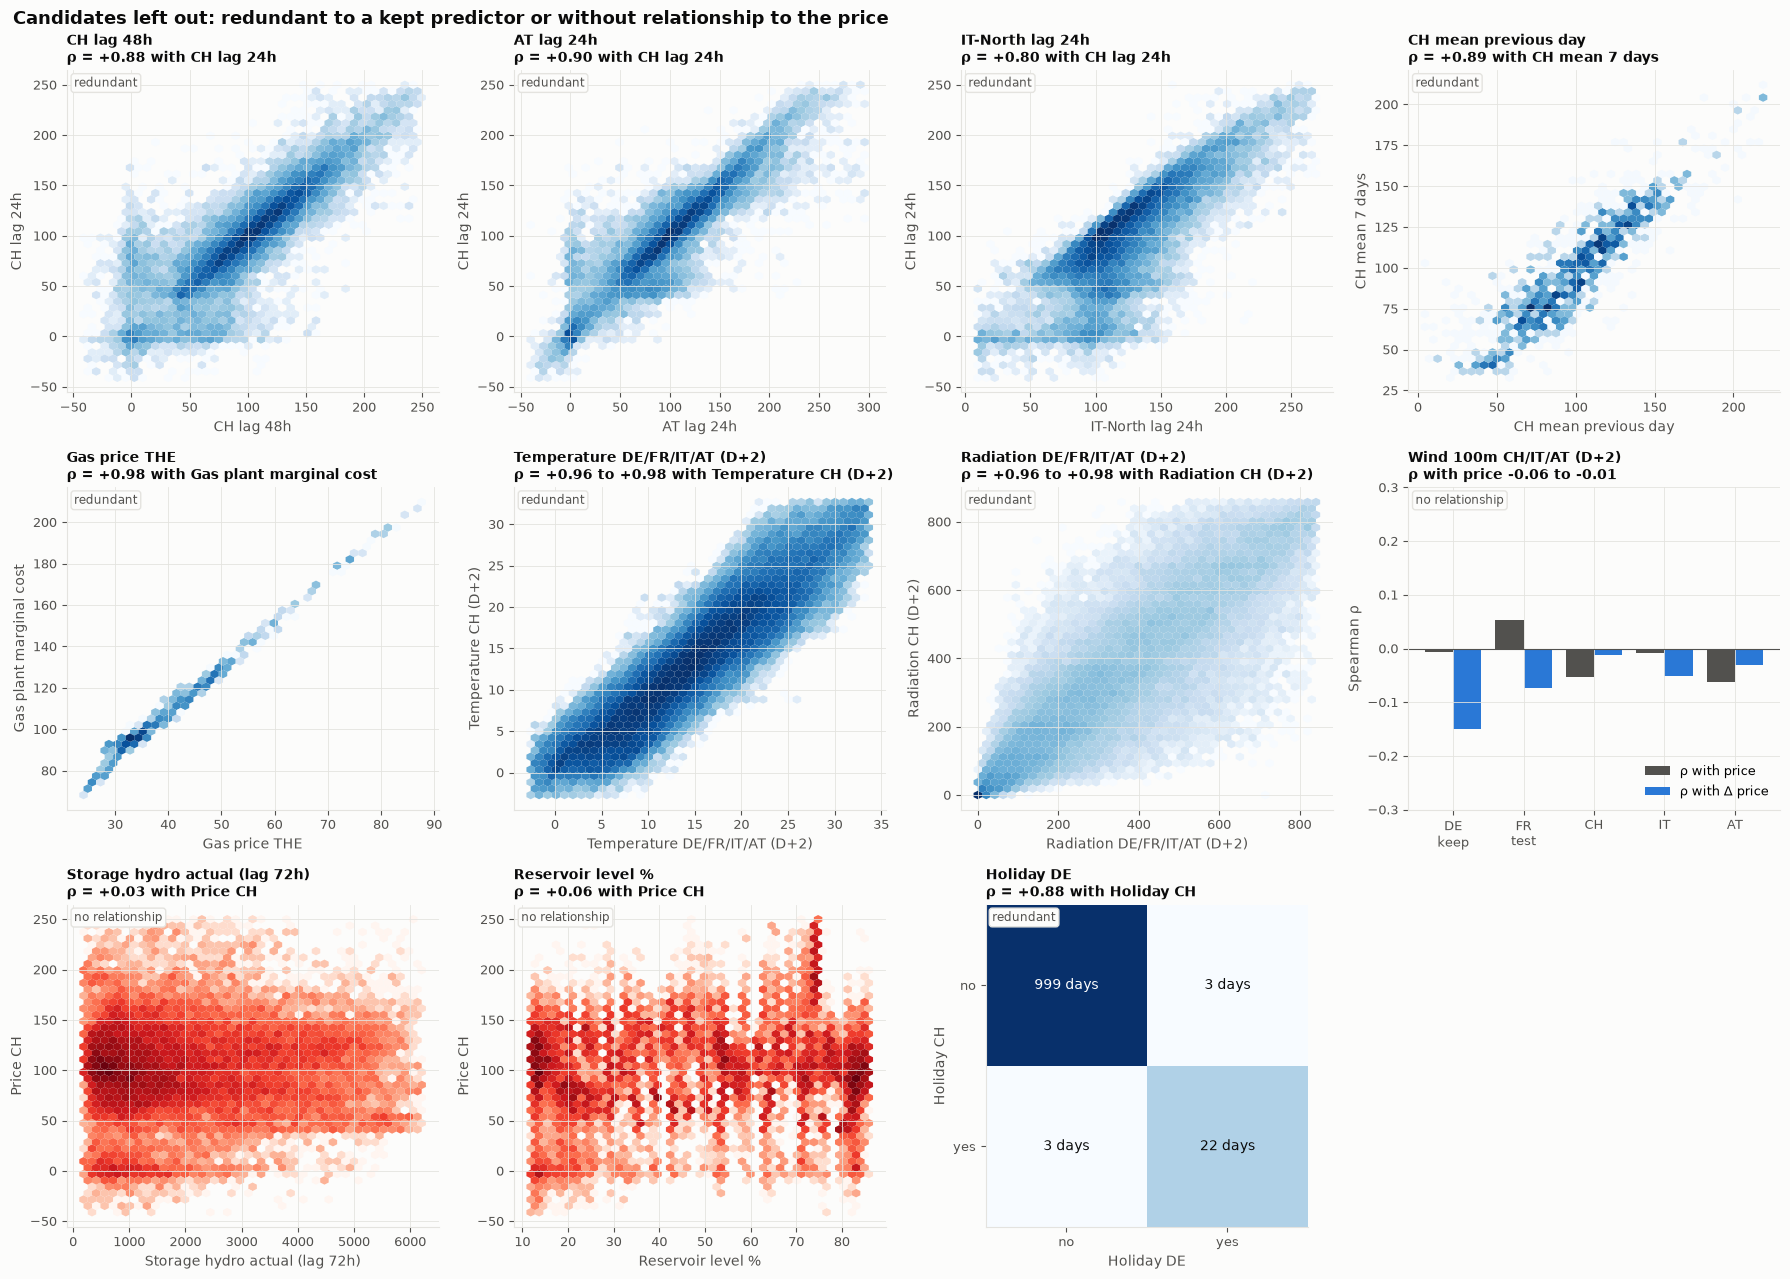

In [13]:
FOREIGN = ("DE", "FR", "IT", "AT")
DROP_PANELS = {  # title: (candidates, reference, kind)
    "CH lag 48h": (["CH lag 48h"], "CH lag 24h", "redundant"),
    "AT lag 24h": (["AT lag 24h"], "CH lag 24h", "redundant"),
    "IT-North lag 24h": (["IT-North lag 24h"], "CH lag 24h", "redundant"),
    "CH mean previous day": (["CH mean previous day"], "CH mean 7 days", "redundant"),
    "Gas price THE": (["Gas price THE"], "Gas plant marginal cost", "redundant"),
    "Temperature DE/FR/IT/AT (D+2)": ([f"Temperature {c} (D+2)" for c in FOREIGN], "Temperature CH (D+2)", "redundant"),
    "Radiation DE/FR/IT/AT (D+2)": ([f"Radiation {c} (D+2)" for c in FOREIGN], "Radiation CH (D+2)", "redundant"),
    "Wind 100m CH/IT/AT (D+2)": ([f"Wind 100m {c} (D+2)" for c in ("CH", "IT", "AT")], dp.TARGET, "wind per country"),
    "Storage hydro actual (lag 72h)": (["Storage hydro actual (lag 72h)"], dp.TARGET, "no relationship"),
    "Reservoir level %": (["Reservoir level %"], dp.TARGET, "no relationship"),
    "Holiday DE": (["Holiday DE"], "Holiday CH", "redundant"),
}
KIND_COLOR = {"redundant": "Blues", "no relationship": "Reds"}


def tag(ax, text):
    ax.text(0.02, 0.98, text, transform=ax.transAxes, va="top", fontsize=8.5, color=INK_2,
            bbox=dict(boxstyle="round,pad=0.25", fc=SURFACE, ec=GRID))


fig, axes = plt.subplots(3, 4, figsize=(18, 13))
for ax, (title, (feats_, ref, kind)) in zip(axes.flat, DROP_PANELS.items()):
    rhos = [corr.loc[f, ref] for f in feats_]
    rho_txt = f"{rhos[0]:+.2f}" if len(rhos) == 1 else f"{min(rhos):+.2f} to {max(rhos):+.2f}"
    if kind == "wind per country":
        winds = [f"Wind 100m {c} (D+2)" for c in ("DE", "FR", "CH", "IT", "AT")]
        labels = ["DE\nkeep", "FR\ntest", "CH", "IT", "AT"]
        x = np.arange(len(winds))
        ax.bar(x - 0.2, corr.loc[winds, dp.TARGET], width=0.4, color=INK_2, label="ρ with price")
        ax.bar(x + 0.2, corr.loc[winds, dp.TARGET_DELTA], width=0.4, color=COLORS[0], label="ρ with Δ price")
        ax.axhline(0, color=INK_2, linewidth=0.8)
        ax.set_xticks(x, labels)
        ax.set_ylim(-0.3, 0.3)
        ax.set_ylabel("Spearman ρ")
        ax.legend(loc="lower right")
        ax.set_title(f"{title}\nρ with price {rho_txt}", fontsize=10)
        tag(ax, "no relationship")
        continue
    d = pd.concat([candidates[[f, ref]].set_axis(["x", "y"], axis=1) for f in feats_]).dropna()
    if d["x"].nunique() <= 2:  # binary: cross table
        tab = pd.crosstab(d["y"].map({0: "no", 1: "yes"}), d["x"].map({0: "no", 1: "yes"})) / 24
        tab = tab.loc[["no", "yes"], ["no", "yes"]]
        ax.imshow(np.log1p(tab.to_numpy()), cmap=KIND_COLOR[kind])
        for (i, j), v in np.ndenumerate(tab.to_numpy()):
            ax.text(j, i, f"{v:,.0f} days", ha="center", va="center", fontsize=10,
                    color="white" if v > 100 else INK)
        ax.set_xticks([0, 1], tab.columns)
        ax.set_yticks([0, 1], tab.index)
        ax.grid(False)
    else:
        lo, hi = d.quantile(0.005), d.quantile(0.995)
        d = d[(d >= lo).all(axis=1) & (d <= hi).all(axis=1)]
        ax.hexbin(d["x"], d["y"], gridsize=40, bins="log", cmap=KIND_COLOR[kind], mincnt=1, linewidths=0)
    ax.set_xlabel(title)
    ax.set_ylabel(ref)
    ax.set_title(f"{title}\nρ = {rho_txt} with {ref}", fontsize=10)
    tag(ax, kind)
for ax in axes.flat[len(DROP_PANELS):]:
    ax.axis("off")
fig.suptitle("Candidates left out: redundant to a kept predictor or without relationship to the price",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
save(fig, "05_dropped_predictors.png")
rows = {f: r for fs, r, _ in DROP_PANELS.values() for f in fs}
pd.DataFrame({"Compared with": rows,
              "ρ with price": {f: corr.loc[f, dp.TARGET] for f in rows},
              "ρ with Δ price": {f: corr.loc[f, dp.TARGET_DELTA] for f in rows},
              "ρ with reference": {f: corr.loc[f, r] for f, r in rows.items()},
              }).style.format({"ρ with price": "{:+.2f}", "ρ with Δ price": "{:+.2f}", "ρ with reference": "{:+.2f}"})

**What we see:**
- **Prices:** CH lag 48h, AT and IT-North of yesterday lie close to the diagonal with CH lag 24h
  (ρ 0.80–0.90). CH mean previous day lies close to CH mean 7 days (ρ 0.89).
- **Gas price THE** lies almost exactly on one line with the gas-plant marginal cost (ρ 0.98),
  because the latter is computed as 2 × gas price + 0.4 × CO2 price and the gas part dominates.
- **Temperature and radiation abroad** lie on the diagonal with Switzerland (ρ 0.96–0.98). The
  weather is large-scale; the Swiss series represents them all.
- **Wind per country:** only German wind relates to the price change (ρ −0.15), French wind weakly
  (−0.07). Wind in CH, IT and AT shows |ρ| ≤ 0.06 for both; there is hardly any wind power there
  (CH ~18 MW on average).
- **Storage hydro actual** and **reservoir level %:** shapeless clouds (ρ ≤ 0.06). Storage hydro is
  produced exactly when the price is high; three days old it says nothing about D+2. Reservoir
  level % is pure season (ρ −0.93 with month); the anomaly stays.
- **Holiday DE:** on 22 of 28 days it is also a holiday in Switzerland; the others hardly matter
  for the price.

## 6 Conclusion: suggested predictors

| Decision | Predictors | Reason |
|---|---|---|
| **keep** | CH lag 24h, CH lag 168h, CH mean 7 days | strongest available signals (ρ 0.74–0.88); lag 168h adds the weekly pattern (autocorrelation, EDA 5.4) |
| **keep** | Temperature CH, Radiation CH (D+2) | weather forecast for D+2; ρ ≈ −0.3 with the price. Representative for temperature and radiation of all neighbouring countries (ρ 0.93–0.98) |
| **keep** | Wind 100m DE (D+2) | hardly related to the level, but to the change (ρ −0.15): more wind than yesterday → cheaper |
| **keep** | Gas plant marginal cost | ρ 0.57; explains the price level. Replaces the gas price (ρ 0.98 with each other) |
| **keep** | Reservoir level anomaly | ρ −0.59: less water than usual → higher prices. To be checked in the model because of the short series |
| **keep** | Hour, weekend, holiday CH, month | not monotonic, but central for the daily shape; weekend is the strongest signal for Δ price (ρ −0.34) |
| **drop** (5.3) | CH lag 48h, AT lag 24h, IT-North lag 24h, CH mean previous day | almost the same information as CH lag 24h or CH mean 7 days (ρ 0.80–0.90) |
| **drop** (5.3) | Gas price THE, holiday DE | redundant to a kept predictor (ρ 0.88–0.98) |
| **drop** (5.3) | Temperature and radiation DE, FR, IT, AT (D+2) | large-scale weather, almost identical to Switzerland (ρ 0.93–0.98) |
| **drop** (5.3) | Wind 100m CH, IT, AT (D+2) | no relationship with price or change (|ρ| ≤ 0.06); hardly any wind power |
| **drop** (5.3) | Reservoir level %, storage hydro actual | no relationship with the price (ρ ≤ 0.06); reservoir level % is pure season (ρ −0.93 with month) |
| **not available** | neighbouring prices same hour* | strongest relationship (AT ρ 0.90), but unknown for D+2. Forecasting them would be the same task as the Swiss price |
| **test in model** | DE lag 24h, FR lag 24h, wind 100m FR (D+2), CO2 price, nuclear CH/FR, run-of-river, net import, precipitation 7 days | weak or slow signals; kept only if they lower the error on a separate test period |

Of 46 candidates, **14 are kept**, **19 are dropped**, 4 are not available and 9 are tested in the
model.

The matrix does not replace model selection: a tree model can use interactions (e.g. solar matters
only at midday) that a pairwise correlation does not show. The list is therefore the starting point
for `03_modeling.ipynb`, where the groups are added step by step and evaluated on a holdout.

## 7 Pretest: is the weather forecast worth it, and which model?

**Why this test?** Two decisions of the data preparation should not rest on correlations alone:
whether the effort with the archived weather forecasts pays off, and which type of model fits.
**Training 18.02.2024 – 30.09.2025, test from 01.10.2025** (separated in time, as in `analysis/`).
The measure is nMAE = mean absolute error / mean absolute price. The actual modelling with tuning
follows in `03_modeling.ipynb`; the numbers here are for comparison with each other.

**Target = change against the previous day.** The price level rises in the test period (2026:
~128 EUR/MWh) above almost all training values. Tree models cannot extrapolate beyond the training
range and would systematically forecast too low. All models therefore predict the **change against
the previous day** (price − CH lag 24h); the forecast is CH lag 24h + predicted change. In addition
there are **Δ predictors**: how the forecasts change against the previous day (e.g. more wind than
yesterday → cheaper).

**What we want to analyse:**
1. **What is the weather forecast worth?** XGBoost with the kept predictors
   - *without* forecasts for D+2,
   - *with the weather forecast* (kept: temperature CH, radiation CH, wind DE),
   - *with the weather forecast of all countries* (all 15 weather series, to check the selection),
   - *with the TSO forecast* (residual load, solar, wind; too optimistic: pretends that the
     forecast for D+1 were already known for D+2).
2. **Which model?** Multiple linear regression, random forest and XGBoost with the same predictors
   (kept ones including the weather forecast).

The reference is the naive forecast "price as on the previous day".

Training 13,916 h, test 9,210 h; naive forecast (previous-day price): 14.4 %


nMAE [%]
Forecasts without forecasts for D+2            13.26
          weather forecast (selected)          11.82
          weather forecast (all countries)     11.47
          TSO forecast (not available)         11.15
Model     Multiple linear regression           11.97
          Random forest                        12.01
          XGBoost                              11.82

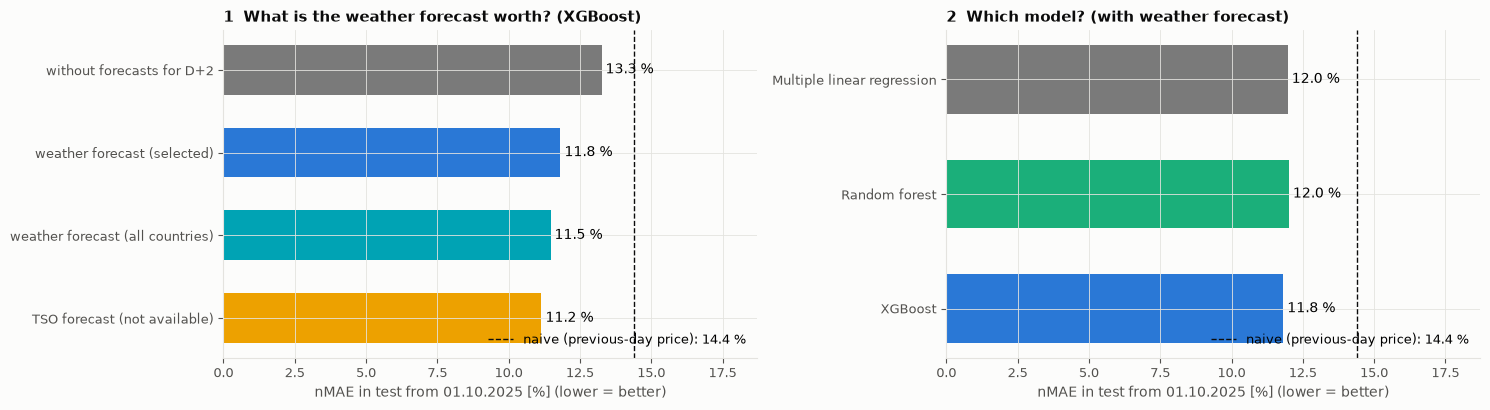

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

BASE = [c for c in dp.KEEP if "(D+2)" not in c]
WX = [c for c in dp.KEEP if "(D+2)" in c]
WX_ALL = dp.GROUPS["Weather CH (D+2)"][:3] + dp.GROUPS["Weather abroad (D+2)"]
tso = dp.tso_features(hourly)
TSO = [c for c in tso if c.startswith("Residual load")] + ["Solar CH TSO", "Wind DE TSO"]
TEST_START = pd.Timestamp("2025-10-01", tz=dp.TZ).tz_convert("UTC")

forecasts = candidates[WX_ALL].join(tso[TSO])
delta = (forecasts - forecasts.shift(24)).add_prefix("Δ ")
data = candidates[BASE + [dp.TARGET]].join(forecasts).join(delta).loc["2024-02-18":].dropna()
train, test = data[data.index < TEST_START], data[data.index >= TEST_START]
y_train = train[dp.TARGET] - train["CH lag 24h"]
scale = test[dp.TARGET].abs().mean()


def with_delta(cols):
    return cols + [f"Δ {c}" for c in cols]


def xgb():
    return XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=5, min_child_weight=50, reg_lambda=10,
                        subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=-1)


def fit_score(model, cols):
    pred = test["CH lag 24h"] + model.fit(train[cols], y_train).predict(test[cols])
    return 100 * np.abs(pred - test[dp.TARGET]).mean() / scale


naive = 100 * np.abs(test["CH lag 24h"] - test[dp.TARGET]).mean() / scale
variants = pd.Series({
    "without forecasts for D+2": fit_score(xgb(), BASE),
    "weather forecast (selected)": fit_score(xgb(), BASE + with_delta(WX)),
    "weather forecast (all countries)": fit_score(xgb(), BASE + with_delta(WX_ALL)),
    "TSO forecast (not available)": fit_score(xgb(), BASE + with_delta(TSO)),
})
models = pd.Series({
    "Multiple linear regression": fit_score(LinearRegression(), BASE + with_delta(WX)),
    "Random forest": fit_score(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1,
                                                     random_state=0), BASE + with_delta(WX)),
    "XGBoost": variants["weather forecast (selected)"],
})
print(f"Training {len(train):,} h, test {len(test):,} h; naive forecast (previous-day price): {naive:.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, res, title, colors in (
        (axes[0], variants, "1  What is the weather forecast worth? (XGBoost)",
         [COLORS[8], COLORS[0], COLORS[9], COLORS[3]]),
        (axes[1], models, "2  Which model? (with weather forecast)", [COLORS[8], COLORS[2], COLORS[0]])):
    ax.barh(res.index, res, color=colors, height=0.6)
    ax.axvline(naive, color=INK, linestyle="--", linewidth=1, label=f"naive (previous-day price): {naive:.1f} %")
    ax.legend(loc="lower right")
    for i, v in enumerate(res):
        ax.text(v, i, f" {v:.1f} %", va="center", fontsize=10)
    ax.invert_yaxis()
    ax.set_xlabel("nMAE in test from 01.10.2025 [%] (lower = better)")
    ax.set_title(title, fontsize=11)
    ax.set_xlim(0, max(naive, res.max()) * 1.3)
save(fig, "06_pretest.png")
pd.concat({"Forecasts": variants, "Model": models}).rename("nMAE [%]").to_frame().round(2)

**What we see:**
- Even **without** forecasts for D+2, XGBoost beats the naive forecast (lags, calendar, reservoir
  level and gas are enough for that).
- The **weather forecast** lowers the error clearly and recovers most of what the TSO forecast would
  bring. With all countries the error is slightly lower than with the selection; which weather
  series are worth it is checked in `03_modeling` (e.g. wind FR).
- The **TSO forecast** would be slightly better again, but is not available for D+2. A model using
  it would look better by this margin than it would be in operation.
- **Model:** XGBoost is slightly ahead of random forest and linear regression (11.8 % vs 12.0 %
  each). The linear regression is only this good because the target is the change against the
  previous day and the lags already provide the level. Untuned, the margins are small; the tuning in
  `03_modeling` decides.